### NumPy

**NumPy** (Numerical Python) es la biblioteca de cómputo numérico de Python. Sus operaciones están implementadas en C, así que puede hacer cálculos sobre millones de datos mucho más rápido que las listas nativas, y además permite escribir las operaciones casi igual que en matemáticas, vectores, matrices y sistemas de ecuaciones.
___

In [40]:
import numpy as np
import matplotlib.pyplot as plt

___
#### ¿Por qué NumPy y no listas?

Ya conoces las listas. Hay dos razones para no usarlas en cálculo numérico: las listas no saben de matemáticas y son lentas.

In [2]:
lista = [1,2,3]
arreglo = np.array([1,2,3])

print(lista + lista)
print(arreglo + arreglo)

[1, 2, 3, 1, 2, 3]
[2 4 6]


In [3]:
# un millón de números en una lista y en un array
lista_grande = list(range(1000000))
arreglo_grande = np.arange(1000000)

In [4]:
%timeit [num * 2 for num in lista_grande]

27.1 ms ± 655 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [5]:
%timeit arreglo_grande * 2

1.04 ms ± 9.86 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


La versión con NumPy es decenas de veces más rápida y se escribe en una línea. A esto se le llama **vectorizar**, en lugar de recorrer los elementos con un ciclo, la operación se aplica al array completo.

___
#### Crear arrays

In [22]:
# a partir de una lista
a = np.array([1, 2, 3])

# de ceros y de unos
b = np.zeros(5)
c = np.ones(15)

# rangos
d = np.linspace(0, 10, 11) # inicio, final, numero de elementos
e = np.arange(0,10, 0.5) # inicio, final, tamaño de paso


print(a)
print(b)
print(c)
print(d)
e

[1 2 3]
[0. 0. 0. 0. 0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
[ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]


array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. , 5.5, 6. ,
       6.5, 7. , 7.5, 8. , 8.5, 9. , 9.5])

In [25]:
# arrays 2D: la forma se da como una tupla (filas, columnas)
A = np.array([[1,1],
              [1,1]])

zeros = np.zeros((3,3))

identidad = np.eye(3)
identidad

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

Todo array tiene tres atributos que conviene revisar siempre que algo no funcione:

- `shape`: la forma, una tupla con el tamaño de cada dimensión
- `ndim`: el número de dimensiones
- `dtype`: el tipo de dato. A diferencia de las listas, **todos los elementos de un array son del mismo tipo**

In [29]:
print(a.shape, a.ndim, a.dtype)
print(A.shape, A.ndim, A.dtype)

mezcla = np.array([1, 2.5, 5])
mezcla.dtype

(3,) 1 int64
(2, 2) 2 int64


dtype('float64')

___
#### Operaciones vectorizadas y broadcasting

Las operaciones aritméticas se aplican elemento a elemento. Cuando operas un array con un número, NumPy "estira" el número para que tenga la misma forma que el array. A eso se le llama **broadcasting**.

In [30]:
# temperaturas de °C a K, el 273.15 se suma a cada elemento
Tc = np.array([25.0, 37.0, 100.0])
Tk = Tc + 273.15

Tk

array([298.15, 310.15, 373.15])

In [34]:
# las funciones matemáticas de NumPy también se aplican a todo el array
np.sqrt(Tk)
np.exp(Tk)
np.log(Tk)
np.sin(Tk)

array([0.29676389, 0.76282617, 0.64385491])

El error más común en NumPy aparece cuando las formas no son compatibles. Es decir, tienen longitud diferente

In [35]:
np.array([25.0, 37.0, 100.0]) + np.array([25.0, 37.0])

ValueError: operands could not be broadcast together with shapes (3,) (2,) 

___
##### Ejercicio
En espectroscopía infrarroja las bandas se reportan en número de onda $\tilde{\nu}$ (cm⁻¹). Convierte el array de números de onda a longitud de onda en µm y a frecuencia en Hz:

$$\lambda\,(\mu m) = \frac{10^4}{\tilde{\nu}\,(cm^{-1})} \qquad\qquad \nu\,(Hz) = c\,\tilde{\nu}, \quad c = 2.998 \times 10^{10}\ cm/s$$

In [37]:
num_onda = np.array([3300, 2950, 1715, 1600])   # cm^-1: O-H, C-H, C=O, C=C

lon_onda = 1e4 / num_onda
frec = 2.99e10 * num_onda

print(lon_onda)
print(frec)

[3.03030303 3.38983051 5.83090379 6.25      ]
[9.86700e+13 8.82050e+13 5.12785e+13 4.78400e+13]


___
#### Gráficas rápidas

Con un array de $x$ y una función puedes graficar en dos líneas. Las imágenes se generan con la biblioteca de visualización Matplotlib. NumPy trae todas las funciones matemáticas usuales: https://numpy.org/doc/stable/reference/routines.math.html

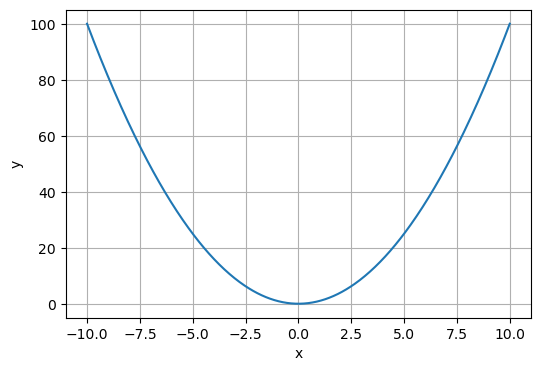

In [43]:
x = np.linspace(-10, 10, 500)
y = x**2

plt.figure(figsize=(6,4))
plt.plot(x,y)
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.show()

In [44]:
def amortiguado(t):
    return np.cos(2 * t) * np.exp(-t / 4)

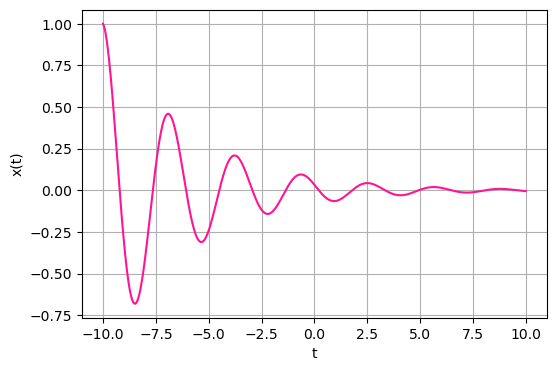

In [45]:
t = np.linspace(0, 20, 500)

plt.figure(figsize=(6,4))
plt.plot(x,amortiguado(t), color='deeppink')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.grid()
plt.show()

___
#### Indexado, cortes y máscaras

Igual que en las listas, se accede a los elementos por su índice **[idx]** y se extraen pedazos con el formato **[inicio : fin : paso]**.

In [52]:
g = np.array([1, 5, 6, 8, 16, 64, 1, 0])

#primer elemento
print(g[0])

#ultimo elemento
print(g[-1])

# quiero del idx 2 al 4
print(g[2:5])

# del idx 2 en adelante de dos en dos
print(g[2::2])

#al reves
print(g[::-1])

#y si quiero varios indices
print(g[[0,3,5]])

1
0
[ 6  8 16]
[ 6 16  1]
[ 0  1 64 16  8  6  5  1]
[ 1  8 64]


**Cuidado:** un corte de un array **no es una copia**, es una vista del mismo array. Si modificas el corte, modificas el original. En las listas no pasa esto.

In [56]:
copia = g.copy()
g[0] = 1

print(copia)
print(g)

[999   5   6   8  16  64   1   0]
[ 1  5  6  8 16 64  1  0]


##### Máscaras booleanas

Una comparación devuelve un array de `True` y `False` con la misma forma. Ese array se puede usar como **máscara** para filtrar. Es la herramienta más usada de NumPy.

In [59]:
mascara = g < 8 

print(mascara)
g[mascara]

g[g<8]

[ True  True  True False False False  True  True]


array([1, 5, 6, 1, 0])

___
##### Ejercicio
Dado un array con pesos moleculares en g/mol, usa una máscara para obtener cuáles son mayores a 60 g/mol y cuántas son.

In [60]:
# agua, metano, metanol, etanol, acetona, benceno, glucosa
pesos = np.array([18.02, 16.04, 32.04, 46.07, 58.08, 78.11, 180.16])

grandes = pesos > 60
print(grandes)
print(pesos[grandes])
print(f'{grandes.sum()} de {len(pesos)} son moléculas grandes') 

[False False False False False  True  True]
[ 78.11 180.16]
2 de 7 son moléculas grandes


___
#### Estadística básica y números aleatorios

Para generar números aleatorios se crea un **generador** con una semilla. Con la misma semilla salen los mismos números cada vez, así tus resultados son reproducibles.

In [86]:
# 96 es la semilla
num = np.random.default_rng(96)

# uniformes entre 0 y 1
num.random(3)

# enteros entre 1 y 6, como dados
num.integers(1, 7, size=10)

# distribución normal con media 8 y desviación estándar 5
h = num.normal(8, 5, size=1000)

In [87]:
print('media:', h.mean())
print('desviación estándar:', h.std())
print('mínimo:', h.min(), ' máximo:', h.max())
print('mediana:', np.median(h))

media: 7.82468753128427
desviación estándar: 4.698718013962672
mínimo: -5.986169958996912  máximo: 23.545031941443153
mediana: 7.933566405631351


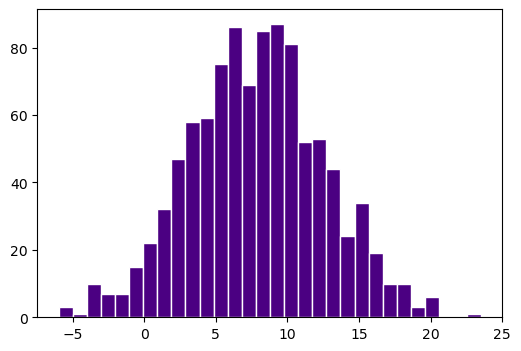

In [88]:
plt.figure(figsize=(6,4))
plt.hist(h, bins=30, color='indigo', edgecolor='white')
plt.show()

___
#### Arrays 2D y el argumento axis

Un array 2D es una tabla: filas y columnas. Se indexa con dos índices **[fila, columna]** y cada uno acepta cortes.

In [89]:
A = np.array([[1, 0, 6],
              [8, 5, 9],
              [7, 3, 0]])

print(A.shape, A.ndim, A.size)

(3, 3) 2 9


In [94]:
# fila 0, columna 1
print(A[0,1])

# fila 1 completa (igual que A[1, :])
print(A[1])

# columna 0 completa
print(A[:,0])

# subbloque: dos primeras filas, dos últimas columnas
print(A[:2, 1:])

0
[8 5 9]
[1 8 7]
[[0 6]
 [5 9]]


In [97]:
# cambiar de forma: reshape reacomoda los mismos datos
v = np.arange(12)
M = v.reshape(3,4)
print(M)

# aplanar de regreso a 1D
M.ravel()

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]


array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

___
##### Sistemas de ecuaciones

Un sistema lineal se escribe como $B\vec{x} = \vec{b}$ y se resuelve con `np.linalg.solve`:

$$\begin{cases} 3x + 2y + z = 4 \\ 5x - 5y + 4z = 3 \\ 6x + z = 0 \end{cases}
\qquad\qquad
\begin{pmatrix} 3 & 2 & 1 \\ 5 & -5 & 4 \\ 6 & 0 & 1 \end{pmatrix}
\begin{pmatrix} x \\ y \\ z \end{pmatrix} =
\begin{pmatrix} 4 \\ 3 \\ 0 \end{pmatrix}$$

In [100]:
B = np.array([[3,  2, 1],
              [5, -5, 4],
              [6,  0, 1]])

b = np.array([4, 3, 0])

sln = np.linalg.solve(B, b)
x, y, z = sln

print(f'x = {x:.4f}, y = {y:.4f}, z = {z:.4f}')

x = -0.4906, y = 1.2642, z = 2.9434
